# Hydrogen impurities in dense-phase CO₂: fluid exposure and crack-growth sensitivity

**Version 1.0.0 · Companion to [NeqSim #4544](https://github.com/equinor/neqsim/issues/4544)**

[Open in Google Colab](https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/colab/co2-well-integrity-4509/notebooks/fluidflow/co2_h2_impurity_fatigue_fracture_4544.ipynb)

Use a source-built NeqSim runtime to connect CO₂–H₂ composition, phase behaviour and hydrogen
fugacity to an explicit, synthetic fracture-mechanics sensitivity. Keep the composable feed
streams and `ProcessSystem` objects for larger transport studies.

After completing this notebook you can distinguish bulk composition from phase exposure,
compare PR and SRK, audit the current material-screening API, and explain how pressure range,
initial flaw size, crack-growth parameters and toughness change an illustrative cycle count.

**Paper:** Bezensek et al. (2024), *Influence of the H₂ Impurity on the Fatigue Crack Growth
and Fracture in a Dense Phase CO₂ Pipeline*, AMPP-2024-20721,
[DOI 10.5006/C2024-20721](https://doi.org/10.5006/C2024-20721).
The publisher abstract describes X65 tests in dense CO₂ at 100 barg with 2 and 4 mol% H₂,
accelerated crack growth and reduced toughness. Only the abstract was accessible during this
work. Material coefficients, specimen geometry, test temperature, load ratio and individual
measurements were unavailable. This notebook uses 20 °C as a teaching assumption and makes
**no numerical reproduction of those tests**. The abstract's project-specific operating
pressures and pressure-cycle findings are not transferable design limits.

All compositions are mole fractions. NeqSim inputs are absolute pressure; 100 barg is converted
to 101.01325 bara using an explicitly assumed atmospheric pressure of 1.01325 bar. Dry binary
CO₂–H₂ is studied here. Water dropout, acid chemistry, hydrogen uptake kinetics and crack-tip
chemistry are separate mechanisms; see the linked improvement work at the end.

## 1. Reproducible runtime

The commit below was current `equinor/neqsim` master when inspected on 24 October 2026.
The released Python package is only a bridge dependency. Every Java calculation loads from
the source-built JAR; the revision, clean tracked tree, JAR digest and class locations are checked.
Fresh Colab installs missing packages and builds the pinned source. Local validation can supply
`NEQSIM_SOURCE_ROOT` and `NEQSIM_SOURCE_JAR` for that same clean source build.

In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys
import zipfile

NEQSIM_SOURCE_REF = "98d185ded48c5c0c12b2faec374544b6b6b043b1"
os.environ["NEQSIM_JVM_AUTOSTART"] = "0"
requirements = {
    "jpype": "JPype1==1.7.1",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "CoolProp": "CoolProp==7.2.0",
}
missing = [
    requirement
    for module, requirement in requirements.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        check=True,
    )

source_root = Path(os.environ.get("NEQSIM_SOURCE_ROOT", "neqsim-source")).resolve()
if not source_root.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "--filter=blob:none",
            "--no-checkout",
            "https://github.com/equinor/neqsim.git",
            str(source_root),
        ],
        check=True,
        capture_output=True,
        text=True,
    )
    subprocess.run(
        ["git", "checkout", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
source_sha = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=source_root, text=True
).strip()
assert source_sha == NEQSIM_SOURCE_REF, "Source revision differs from the pinned master commit"
assert not subprocess.check_output(
    ["git", "status", "--porcelain", "--untracked-files=no"],
    cwd=source_root,
    text=True,
).strip(), "Tracked source changes would invalidate provenance"

source_jar = Path(
    os.environ.get("NEQSIM_SOURCE_JAR", source_root / "target" / "neqsim-3.26.0.jar")
).resolve()
if not source_jar.is_file():
    build = subprocess.run(
        [
            "bash",
            "mvnw",
            "-q",
            "-DskipTests",
            "-Dmaven.test.skip=true",
            "-Dcheckstyle.skip",
            "-Dspotless.skip=true",
            "-Dmaven.javadoc.skip=true",
            "package",
        ],
        cwd=source_root,
        capture_output=True,
        text=True,
    )
    if build.returncode:
        print(build.stdout[-8000:])
        print(build.stderr[-8000:])
        build.check_returncode()
assert source_jar.is_file(), f"Source-built JAR missing: {source_jar}"
jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()

import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from CoolProp.CoolProp import PropsSI
from IPython.display import Markdown, display

pd.set_option("display.max_columns", None)

assert not jpype.isJVMStarted(), "Restart the runtime before loading a different NeqSim build"
jpype.addClassPath(str(source_jar))
jpype.startJVM("-Xrs", "-Xmx2g", convertStrings=True)
JClass = jpype.JClass
SystemPrEos = JClass("neqsim.thermo.system.SystemPrEos")
SystemSrkEos = JClass("neqsim.thermo.system.SystemSrkEos")
ThermodynamicOperations = JClass("neqsim.thermodynamicoperations.ThermodynamicOperations")
Stream = JClass("neqsim.process.equipment.stream.Stream")
ProcessSystem = JClass("neqsim.process.processmodel.ProcessSystem")
PipeBeggsAndBrills = JClass("neqsim.process.equipment.pipeline.PipeBeggsAndBrills")
TransientWellbore = JClass("neqsim.process.equipment.pipeline.TransientWellbore")
CO2InjectionWellAnalyzer = JClass("neqsim.process.equipment.pipeline.CO2InjectionWellAnalyzer")
ImpurityMonitor = JClass("neqsim.process.measurementdevice.ImpurityMonitor")

for java_class in (SystemPrEos, TransientWellbore, CO2InjectionWellAnalyzer):
    origin_uri = java_class.class_.getProtectionDomain().getCodeSource().getLocation().toURI()
    origin = Path(str(JClass("java.io.File")(origin_uri).getPath())).resolve()
    assert origin == source_jar, (java_class, origin)

provenance = {
    "neqsim_source_repository": "https://github.com/equinor/neqsim",
    "neqsim_source_ref": source_sha,
    "jar_sha256": jar_sha256,
    "java": str(jpype.java.lang.System.getProperty("java.version")),
    "python": sys.version.split()[0],
    "packages": {
        package: importlib.metadata.version(package)
        for package in ("JPype1", "numpy", "pandas", "matplotlib", "CoolProp")
    },
    "class_origin_verified": True,
}
print(json.dumps(provenance, indent=2))
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False})
results_dir = Path("co2_h2_integrity_results")
results_dir.mkdir(exist_ok=True)
HydrogenMaterialAssessment = JClass("neqsim.process.corrosion.HydrogenMaterialAssessment")


{
  "neqsim_source_repository": "https://github.com/equinor/neqsim",
  "neqsim_source_ref": "98d185ded48c5c0c12b2faec374544b6b6b043b1",
  "jar_sha256": "79bbf5b193922223f6fb920ff6897d51e7ce3f32ab83ccb3152952b8c01c4bd1",
  "java": "17.0.20",
  "python": "3.12.14",
  "packages": {
    "JPype1": "1.7.1",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2",
    "CoolProp": "7.2.0"
  },
  "class_origin_verified": true
}


## 2. Fluid exposure at the paper's nominal pressure

PR and SRK use the classic mixing rule and the binary parameters in the pinned NeqSim database.
They are model comparisons, not experimental validation. Density alone does not identify a
phase, and a native gas tag is not a vapour quality for a supercritical fluid.

For component hydrogen in phase $k$, the EOS returns a fugacity coefficient $\phi_k$:

$$f_{H_2,k}=x_{H_2,k}\phi_{H_2,k}P$$

Here $x$ is phase mole fraction, $P$ is pressure in bara and $f$ is fugacity in bar on the EOS
reference convention. Bulk $z_{H_2}P$ is only a pressure-based exposure proxy, not an EOS
fugacity or a separately applied gauge pressure. Neither quantity predicts embrittlement alone.

In [2]:
ATMOSPHERIC_BAR = 1.01325
PAPER_PRESSURE_BARA = 100.0 + ATMOSPHERIC_BAR
TEMPERATURE_C = 20.0


def make_h2_fluid(temperature_c, pressure_bara, hydrogen_fraction, eos="PR"):
    assert 0.0 <= hydrogen_fraction < 1.0
    constructor = {"PR": SystemPrEos, "SRK": SystemSrkEos}[eos]
    fluid = constructor(temperature_c + 273.15, pressure_bara)
    fluid.addComponent("CO2", 1.0 - hydrogen_fraction)
    if hydrogen_fraction > 0.0:
        fluid.addComponent("hydrogen", hydrogen_fraction)
    fluid.setMixingRule("classic")
    ThermodynamicOperations(fluid).TPflash()
    fluid.initProperties()
    return fluid


def describe_state(fluid, hydrogen_fraction, eos):
    pressure = float(fluid.getPressure("bara"))
    density = float(fluid.getDensity("kg/m3"))
    assert np.isfinite(density) and density > 0.0
    rows = []
    phase_count = int(fluid.getNumberOfPhases())
    balance_errors = []
    components = ["CO2", "hydrogen"] if hydrogen_fraction else ["CO2"]
    for component in components:
        reconstructed = sum(
            float(fluid.getPhase(k).getBeta())
            * float(fluid.getPhase(k).getComponent(component).getx())
            for k in range(phase_count)
        )
        balance_errors.append(abs(reconstructed - float(fluid.getComponent(component).getz())))
    assert max(balance_errors) < 1e-7
    for phase_index in range(phase_count):
        phase = fluid.getPhase(phase_index)
        fraction = float(phase.getBeta())
        phase_density = float(phase.getDensity("kg/m3"))
        phase_hydrogen = 0.0
        coefficient = np.nan
        fugacity = 0.0
        if hydrogen_fraction:
            component = phase.getComponent("hydrogen")
            phase_hydrogen = float(component.getx())
            coefficient = float(component.getFugacityCoefficient())
            fugacity = phase_hydrogen * coefficient * pressure
            assert np.isfinite(fugacity) and fugacity > 0.0
        rows.append(
            {
                "EOS": eos,
                "pressure_bara": pressure,
                "bulk_H2_mol_percent": 100.0 * hydrogen_fraction,
                "bulk_density_kg_m3": density,
                "phase": str(phase.getPhaseTypeName()),
                "phase_mole_fraction": fraction,
                "phase_density_kg_m3": phase_density,
                "phase_H2_mol_percent": 100.0 * phase_hydrogen,
                "H2_phi": coefficient,
                "H2_fugacity_bar": fugacity,
                "bulk_zP_bar": hydrogen_fraction * pressure,
                "phase_count": phase_count,
                "component_residual": max(balance_errors),
            }
        )
    assert abs(sum(row["phase_mole_fraction"] for row in rows) - 1.0) < 1e-8
    return rows


paper_rows = []
feed_models = {}
for eos in ("PR", "SRK"):
    for fraction in (0.0, 0.0075, 0.01, 0.02, 0.04):
        fluid = make_h2_fluid(TEMPERATURE_C, PAPER_PRESSURE_BARA, fraction, eos)
        feed = Stream(f"{eos}-H2-{fraction:g}", fluid)
        feed.setFlowRate(100000.0, "kg/hr")
        process = ProcessSystem()
        process.add(feed)
        process.run()
        feed_models[(eos, fraction)] = (process, feed)
        assert abs(float(feed.getFlowRate("kg/hr")) / 100000.0 - 1.0) < 1e-10
        paper_rows.extend(describe_state(feed.getThermoSystem(), fraction, eos))
paper_states = pd.DataFrame(paper_rows)
display(
    paper_states[
        [
            "EOS",
            "bulk_H2_mol_percent",
            "phase",
            "bulk_density_kg_m3",
            "phase_H2_mol_percent",
            "H2_fugacity_bar",
            "bulk_zP_bar",
        ]
    ].round(4)
)
print("Pressure: 100 barg + 1.01325 bar atmospheric =", PAPER_PRESSURE_BARA, "bara")
print("Maximum component closure residual:", paper_states["component_residual"].max())


Pressure: 100 barg + 1.01325 bar atmospheric = 101.01325 bara
Maximum component closure residual: 0.0


,EOS,bulk_H2_mol_percent,phase,bulk_density_kg_m3,phase_H2_mol_percent,H2_fugacity_bar,bulk_zP_bar
0,PR,0.00,gas,804.7331,0.00,0.0000,0.0000
1,PR,0.75,gas,787.9144,0.75,5.7872,0.7576
2,PR,1.00,gas,782.2060,1.00,7.6122,1.0101
3,PR,2.00,gas,758.8170,2.00,14.3955,2.0203
4,PR,4.00,gas,708.9544,4.00,25.4981,4.0405
5,SRK,0.00,gas,789.0075,0.00,0.0000,0.0000
6,SRK,0.75,gas,771.9212,0.75,6.3611,0.7576
7,SRK,1.00,gas,766.1298,1.00,8.3615,1.0101
8,SRK,2.00,gas,742.4434,2.00,15.7700,2.0203
9,SRK,4.00,gas,692.1771,4.00,27.7793,4.0405


Two-phase sweep states retained: 2


minimum_density_kg_m3  maximum_density_kg_m3  \
EOS bulk_H2_mol_percent                                                 
PR  1.0                               734.9990               898.6475   
    2.0                               705.3896               882.4446   
    4.0                               636.5677               849.5878   
SRK 1.0                               715.4658               893.4823   
    2.0                               685.5103               876.8874   
    4.0                               639.4787               843.3104   

                         minimum_H2_fugacity_bar  maximum_H2_fugacity_bar  
EOS bulk_H2_mol_percent                                                    
PR  1.0                                   6.4799                  11.8885  
    2.0                                  12.0277                  22.9781  
    4.0                                  20.1175                  42.8642  
SRK 1.0                                   7.0206                  13.5595  
    2.0                                  12.9820                  26.1571  
    4.0                                  23.2457                  48.6075

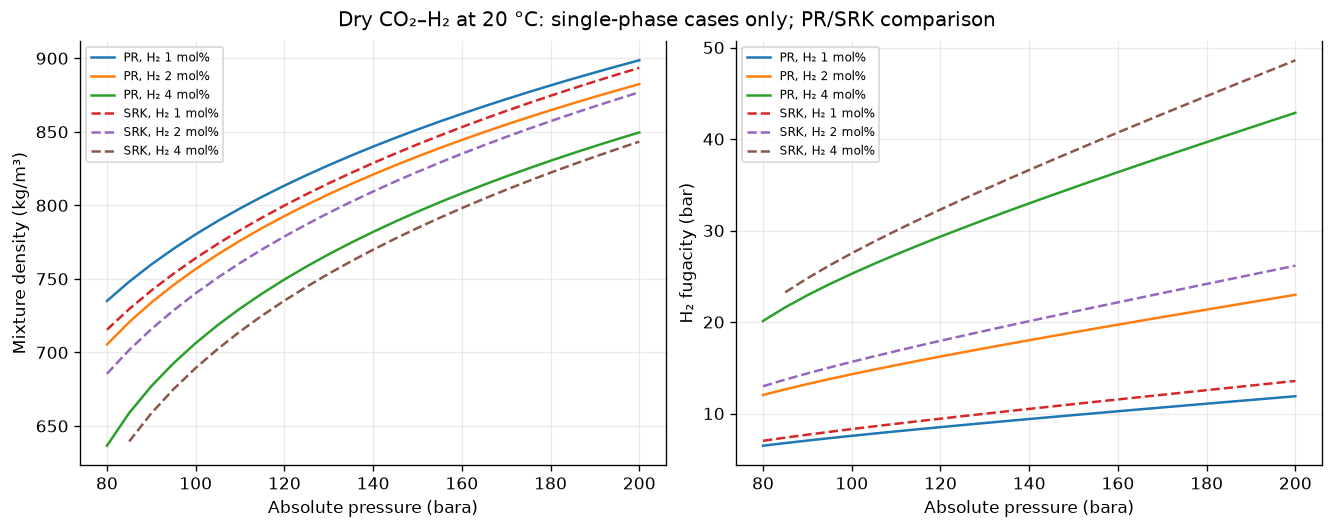

In [3]:
sweep_rows = []
for eos in ("PR", "SRK"):
    for fraction in (0.01, 0.02, 0.04):
        for pressure in np.linspace(80.0, 200.0, 25):
            fluid = make_h2_fluid(TEMPERATURE_C, float(pressure), fraction, eos)
            sweep_rows.extend(describe_state(fluid, fraction, eos))
pressure_sweep = pd.DataFrame(sweep_rows)
single_phase = pressure_sweep.query("phase_count == 1")
display(
    single_phase.groupby(["EOS", "bulk_H2_mol_percent"])
    .agg(
        minimum_density_kg_m3=("bulk_density_kg_m3", "min"),
        maximum_density_kg_m3=("bulk_density_kg_m3", "max"),
        minimum_H2_fugacity_bar=("H2_fugacity_bar", "min"),
        maximum_H2_fugacity_bar=("H2_fugacity_bar", "max"),
    )
    .round(4)
)
print("Two-phase sweep states retained:", len(pressure_sweep.query("phase_count > 1")))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for (eos, fraction), group in single_phase.groupby(["EOS", "bulk_H2_mol_percent"]):
    style = "-" if eos == "PR" else "--"
    label = f"{eos}, H₂ {fraction:g} mol%"
    axes[0].plot(group["pressure_bara"], group["bulk_density_kg_m3"], style, label=label)
    axes[1].plot(group["pressure_bara"], group["H2_fugacity_bar"], style, label=label)
axes[0].set_ylabel("Mixture density (kg/m³)")
axes[1].set_ylabel("H₂ fugacity (bar)")
for axis in axes:
    axis.set_xlabel("Absolute pressure (bara)")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=7)
fig.suptitle("Dry CO₂–H₂ at 20 °C: single-phase cases only; PR/SRK comparison")
fig.savefig(results_dir / "01_density_fugacity.png", dpi=160)
plt.show()


## 3. Phase splitting changes exposure

Scan 40–120 bara at 10 °C with 2 mol% bulk H₂. A two-phase state's gas composition can be
very different from its feed composition. At equilibrium hydrogen fugacity should agree
between phases even though hydrogen mole fractions differ. Check both that agreement and
component conservation before interpreting the phase partitioning.

Maximum interphase relative H2 fugacity difference: 9.458097159679947e-11


,pressure_bara,phase,phase_mole_fraction,phase_H2_mol_percent,H2_fugacity_bar,bulk_zP_bar
7,47.0,gas,0.78222,2.48956,1.74561,0.94
8,47.0,oil,0.21778,0.24163,1.74561,0.94
35,61.0,gas,0.00638,15.65855,13.74506,1.22
36,61.0,oil,0.99362,1.91227,13.74506,1.22


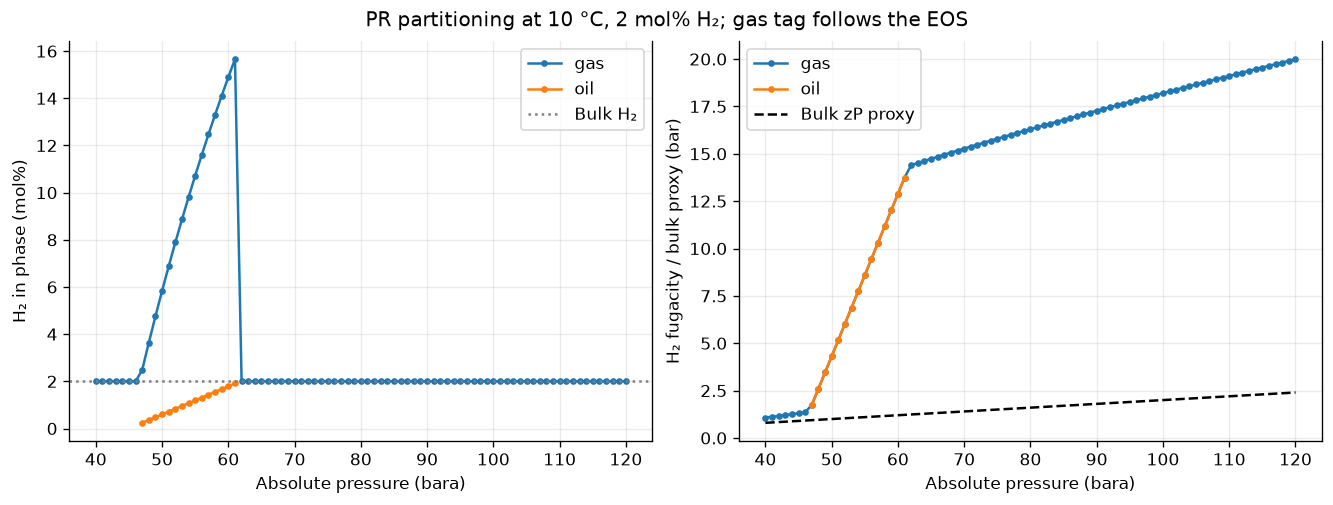

In [4]:
partition_rows = []
fugacity_relative_errors = []
for pressure in np.linspace(40.0, 120.0, 81):
    fluid = make_h2_fluid(10.0, float(pressure), 0.02)
    rows = describe_state(fluid, 0.02, "PR")
    partition_rows.extend(rows)
    if len(rows) > 1:
        fugacities = [row["H2_fugacity_bar"] for row in rows]
        fugacity_relative_errors.append((max(fugacities) - min(fugacities)) / max(fugacities))
partition = pd.DataFrame(partition_rows)
assert fugacity_relative_errors, "This study must include at least one two-phase point"
assert max(fugacity_relative_errors) < 1e-5
print("Maximum interphase relative H2 fugacity difference:", max(fugacity_relative_errors))
two_phase = partition.query("phase_count > 1")
display(
    two_phase.iloc[[0, 1, -2, -1]][
        [
            "pressure_bara",
            "phase",
            "phase_mole_fraction",
            "phase_H2_mol_percent",
            "H2_fugacity_bar",
            "bulk_zP_bar",
        ]
    ].round(5)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
for phase, group in partition.groupby("phase"):
    axes[0].plot(group["pressure_bara"], group["phase_H2_mol_percent"], ".-", label=phase)
    axes[1].plot(group["pressure_bara"], group["H2_fugacity_bar"], ".-", label=phase)
axes[0].axhline(2.0, color="grey", linestyle=":", label="Bulk H₂")
proxy = partition.drop_duplicates("pressure_bara")
axes[1].plot(proxy["pressure_bara"], proxy["bulk_zP_bar"], "k--", label="Bulk zP proxy")
axes[0].set_ylabel("H₂ in phase (mol%)")
axes[1].set_ylabel("H₂ fugacity / bulk proxy (bar)")
for axis in axes:
    axis.set_xlabel("Absolute pressure (bara)")
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle("PR partitioning at 10 °C, 2 mol% H₂; gas tag follows the EOS")
fig.savefig(results_dir / "02_partitioning.png", dpi=160)
plt.show()


## 4. What the native material API currently calculates

`HydrogenMaterialAssessment` supplies categorical screening using composition, pressure,
material strength, hardness, PWHT and a cyclic-service flag. Its thresholds and derating are
not a calibrated CO₂–H₂ crack-growth law. Its `designLifeYears` is documented as report-only.
The code below creates a **new assessment for every fluid**, avoiding the stale-state issue
demonstrated in the following cell. The native category is diagnostic output, not acceptance
of X65, PWHT, or a particular pipeline under a current standard.

In [5]:
material_rows = []
for fraction in (0.0, 0.0075, 0.01, 0.02, 0.04):
    fluid = make_h2_fluid(TEMPERATURE_C, PAPER_PRESSURE_BARA, fraction)
    for cyclic in (False, True):
        assessment = HydrogenMaterialAssessment()
        assessment.setFluid(fluid)
        assessment.setMaterialGrade("X65")
        assessment.setHardnessHRC(20.0)
        assessment.setPwhtApplied(True)
        assessment.setCyclicService(cyclic)
        assessment.setDesignLifeYears(50.0)
        assessment.evaluate()
        material_rows.append(
            {
                "H2_mol_percent": 100.0 * fraction,
                "cyclic_flag": cyclic,
                "native_pressure_proxy_bar": float(assessment.getH2PartialPressureBar()),
                "native_HE_category": str(assessment.getHydrogenEmbrittlementRisk()),
                "native_derating_factor": float(assessment.getHydrogenDeratingFactor()),
                "life_input_years_report_only": float(assessment.getDesignLifeYears()),
            }
        )
material_screen = pd.DataFrame(material_rows)
display(material_screen.round(4))
print("No crack length, load spectrum, growth coefficient or toughness enters this API.")


No crack length, load spectrum, growth coefficient or toughness enters this API.


,H2_mol_percent,cyclic_flag,native_pressure_proxy_bar,native_HE_category,native_derating_factor,life_input_years_report_only
0,0.00,False,0.0000,Negligible,1.0,50.0
1,0.00,True,0.0000,Negligible,1.0,50.0
2,0.75,False,0.7576,Low,1.0,50.0
3,0.75,True,0.7576,Low,1.0,50.0
4,1.00,False,1.0101,Medium,1.0,50.0
5,1.00,True,1.0101,High,1.0,50.0
6,2.00,False,2.0203,Medium,1.0,50.0
7,2.00,True,2.0203,High,1.0,50.0
8,4.00,False,4.0405,Medium,1.0,50.0
9,4.00,True,4.0405,High,1.0,50.0


In [6]:
prior = SystemPrEos(313.15, 10.0)
prior.addComponent("CO2", 0.97)
prior.addComponent("hydrogen", 0.02)
prior.addComponent("H2S", 0.01)
prior.setMixingRule("classic")
ThermodynamicOperations(prior).TPflash()
prior.initProperties()
pure = make_h2_fluid(40.0, 10.0, 0.0)
reused = HydrogenMaterialAssessment()
reused.setFluid(prior)
before_proxy = float(reused.getH2PartialPressureBar())
reused.setFluid(pure)
after_proxy = float(reused.getH2PartialPressureBar())
fresh = HydrogenMaterialAssessment()
fresh.setFluid(pure)
fresh_proxy = float(fresh.getH2PartialPressureBar())
stale_state_diagnostic = pd.DataFrame(
    {
        "assessment_state": [
            "Before fluid replacement",
            "Reused after pure CO2",
            "Fresh pure CO2",
        ],
        "H2_pressure_proxy_bar": [before_proxy, after_proxy, fresh_proxy],
        "expected_for_current_fluid_bar": [0.2, 0.0, 0.0],
    }
)
display(stale_state_diagnostic)
print("Stale H2 state observed:", after_proxy != fresh_proxy)
print("All study cases above use fresh instances; the diagnostic is excluded from predictions.")


Stale H2 state observed: True
All study cases above use fresh instances; the diagnostic is excluded from predictions.


,assessment_state,H2_pressure_proxy_bar,expected_for_current_fluid_bar
0,Before fluid replacement,0.2,0.2
1,Reused after pure CO2,0.2,0.0
2,Fresh pure CO2,0.0,0.0


## 5. Transparent pressure-to-crack calculation

This is a **Python teaching calculation**, not an existing NeqSim integrity engine. Assume a
straight thin wall, mean diameter $D_m=0.60$ m, thickness $t=0.020$ m, a fixed geometry factor
$Y=1.12$, and a small axial flaw of depth $a$. Pressure difference is internal minus external.

$$\Delta\sigma_\theta=\frac{\Delta P D_m}{2t},\qquad \Delta K=Y\Delta\sigma_\theta\sqrt{\pi a}$$

Stress is converted from Pa to MPa before calculating $\Delta K$ in MPa√m. Use the Paris law
with deliberately invented coefficients; $C$ has units m/cycle/(MPa√m)$^m$:

$$\frac{da}{dN}=C(\Delta K)^m$$

For $m=3$, a constant stress range and constant $Y$, the exact cycle count between depths is:

$$N=\frac{2(a_0^{-1/2}-a_f^{-1/2})}{C(Y\Delta\sigma_\theta\sqrt{\pi})^3}$$

The terminal depth is the smaller of wall penetration and the elementary toughness limit
$a_c=(K_{mat}/(Y\sigma_{max}))^2/\pi$. This omits crack-front geometry evolution, plastic
collapse, residual stress, closure, hydrogen diffusion, dwell time and frequency, temperature,
R-ratio dependence and a failure assessment diagram. It cannot certify remaining life.

In [7]:
MEAN_DIAMETER_M = 0.60
WALL_M = 0.020
GEOMETRY_FACTOR = 1.12
INITIAL_FLAW_M = 0.002
MAX_DIFFERENTIAL_BAR = 100.0
MAX_HOOP_MPA = MAX_DIFFERENTIAL_BAR * 1e5 * MEAN_DIAMETER_M / (2 * WALL_M) / 1e6
synthetic_materials = pd.DataFrame(
    [
        {"scenario": "Reference", "C": 1e-12, "Kmat_MPa_sqrt_m": 65.0},
        {"scenario": "Growth sensitivity", "C": 3e-12, "Kmat_MPa_sqrt_m": 65.0},
        {"scenario": "Toughness sensitivity", "C": 1e-12, "Kmat_MPa_sqrt_m": 25.0},
        {"scenario": "Combined sensitivity", "C": 3e-12, "Kmat_MPa_sqrt_m": 25.0},
    ]
)


def terminal_depth(toughness):
    critical = (toughness / (GEOMETRY_FACTOR * MAX_HOOP_MPA)) ** 2 / np.pi
    return min(WALL_M, critical)


def paris_cycles(initial_depth, final_depth, stress_range_mpa, coefficient):
    assert 0 < initial_depth < final_depth <= WALL_M
    assert stress_range_mpa > 0 and coefficient > 0
    factor = coefficient * (GEOMETRY_FACTOR * stress_range_mpa * np.sqrt(np.pi)) ** 3
    return 2.0 * (initial_depth**-0.5 - final_depth**-0.5) / factor


life_rows = []
for material in synthetic_materials.to_dict("records"):
    final_depth = terminal_depth(material["Kmat_MPa_sqrt_m"])
    for pressure_range in (10.0, 30.0, 70.0):
        stress_range = pressure_range * 1e5 * MEAN_DIAMETER_M / (2 * WALL_M) / 1e6
        life_rows.append(
            {
                "scenario": material["scenario"],
                "pressure_range_bar": pressure_range,
                "stress_range_MPa": stress_range,
                "terminal_depth_mm": 1000.0 * final_depth,
                "cycles_synthetic": paris_cycles(
                    INITIAL_FLAW_M, final_depth, stress_range, material["C"]
                ),
            }
        )
life_sensitivity = pd.DataFrame(life_rows)
display(synthetic_materials)
display(life_sensitivity.round(2))
print("Illustrative mean-diameter/thickness:", MEAN_DIAMETER_M / WALL_M)
print("Maximum assumed hoop stress (MPa):", MAX_HOOP_MPA)
print("These scenarios are not assigned to any hydrogen fraction or material grade.")


Illustrative mean-diameter/thickness: 30.0
Maximum assumed hoop stress (MPa): 150.0
These scenarios are not assigned to any hydrogen fraction or material grade.


,scenario,C,Kmat_MPa_sqrt_m
0,Reference,1.000000e-12,65.0
1,Growth sensitivity,3.000000e-12,65.0
2,Toughness sensitivity,1.000000e-12,25.0
3,Combined sensitivity,3.000000e-12,25.0


,scenario,pressure_range_bar,stress_range_MPa,terminal_depth_mm,cycles_synthetic
0,Reference,10.0,15.0,20.00,1.158174e+09
1,Reference,30.0,45.0,20.00,4.289533e+07
2,Reference,70.0,105.0,20.00,3.376601e+06
3,Growth sensitivity,10.0,15.0,20.00,3.860580e+08
4,Growth sensitivity,30.0,45.0,20.00,1.429844e+07
5,Growth sensitivity,70.0,105.0,20.00,1.125534e+06
6,Toughness sensitivity,10.0,15.0,7.05,7.915619e+08
7,Toughness sensitivity,30.0,45.0,7.05,2.931711e+07
8,Toughness sensitivity,70.0,105.0,7.05,2.307761e+06
9,Combined sensitivity,10.0,15.0,7.05,2.638540e+08


,scenario,integration_points,relative_error
0,Reference,1025,7.038388e-06
1,Reference,8193,1.099760e-07
2,Growth sensitivity,1025,7.038388e-06
3,Growth sensitivity,8193,1.099760e-07
4,Toughness sensitivity,1025,7.779075e-07
5,Toughness sensitivity,8193,1.215482e-08
6,Combined sensitivity,1025,7.779075e-07
7,Combined sensitivity,8193,1.215482e-08


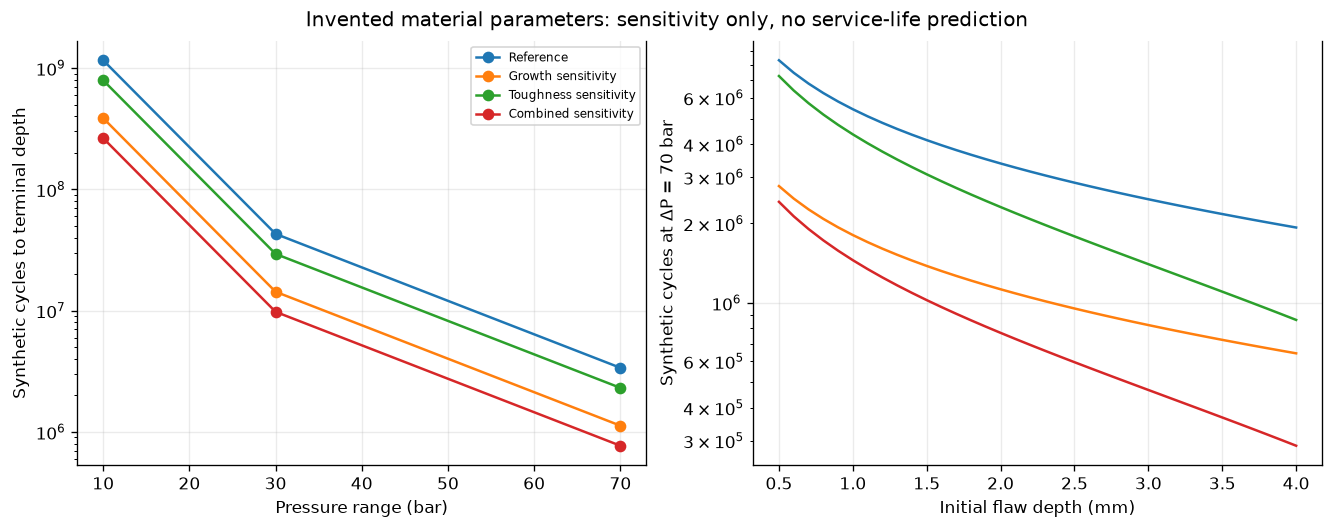

In [8]:
verification_rows = []
for material in synthetic_materials.to_dict("records"):
    final_depth = terminal_depth(material["Kmat_MPa_sqrt_m"])
    stress_range = 105.0
    exact = paris_cycles(INITIAL_FLAW_M, final_depth, stress_range, material["C"])
    for points in (1025, 8193):
        crack_depth = np.linspace(INITIAL_FLAW_M, final_depth, points)
        delta_k = GEOMETRY_FACTOR * stress_range * np.sqrt(np.pi * crack_depth)
        numerical = np.trapezoid(1.0 / (material["C"] * delta_k**3), crack_depth)
        verification_rows.append(
            {
                "scenario": material["scenario"],
                "integration_points": points,
                "relative_error": abs(numerical / exact - 1.0),
            }
        )
integration_check = pd.DataFrame(verification_rows)
assert integration_check.query("integration_points == 8193")["relative_error"].max() < 2e-6
reference_life = life_sensitivity.query("scenario == 'Reference'").set_index("pressure_range_bar")
assert np.isclose(
    reference_life.loc[10.0, "cycles_synthetic"] / reference_life.loc[30.0, "cycles_synthetic"],
    27.0,
)
growth_life = life_sensitivity.query("scenario == 'Growth sensitivity'").set_index(
    "pressure_range_bar"
)
assert np.allclose(reference_life["cycles_synthetic"] / growth_life["cycles_synthetic"], 3.0)
assert np.isclose(70.0 * 1e5 * MEAN_DIAMETER_M / (2 * WALL_M) / 1e6, 105.0)
display(integration_check)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for scenario, group in life_sensitivity.groupby("scenario", sort=False):
    axes[0].semilogy(group["pressure_range_bar"], group["cycles_synthetic"], "o-", label=scenario)
axes[0].set_xlabel("Pressure range (bar)")
axes[0].set_ylabel("Synthetic cycles to terminal depth")
axes[0].legend(fontsize=7)
initial_flaws = np.linspace(0.5, 4.0, 36) / 1000.0
for material in synthetic_materials.to_dict("records"):
    final_depth = terminal_depth(material["Kmat_MPa_sqrt_m"])
    counts = [paris_cycles(depth, final_depth, 105.0, material["C"]) for depth in initial_flaws]
    axes[1].semilogy(1000.0 * initial_flaws, counts, label=material["scenario"])
axes[1].set_xlabel("Initial flaw depth (mm)")
axes[1].set_ylabel("Synthetic cycles at ΔP = 70 bar")
for axis in axes:
    axis.grid(alpha=0.25)
fig.suptitle("Invented material parameters: sensitivity only, no service-life prediction")
fig.savefig(results_dir / "03_crack_growth_sensitivity.png", dpi=160)
plt.show()


## 6. Findings, engineering checks and reusable results

The fluid calculations achieve conservation, phase-equilibrium consistency and model comparison.
They do not achieve experimental CO₂–H₂ validation. The crack calculation agrees with an
analytical integral and exact scaling checks; its physical coefficients remain invented.
Do not map these illustrative cases onto H₂ concentration without measured material data.

In [9]:
tables = {
    "nominal_pressure_states": paper_states,
    "pressure_sweep": pressure_sweep,
    "phase_partitioning": partition,
    "native_material_screen": material_screen,
    "stale_state_diagnostic": stale_state_diagnostic,
    "synthetic_materials": synthetic_materials,
    "crack_growth_sensitivity": life_sensitivity,
    "analytical_integration_check": integration_check,
}
for name, table in tables.items():
    table.to_csv(results_dir / f"{name}.csv", index=False)
validation = {
    "component_residual_max": float(
        max(paper_states["component_residual"].max(), partition["component_residual"].max())
    ),
    "interphase_H2_fugacity_relative_error_max": float(max(fugacity_relative_errors)),
    "analytical_integral_relative_error_max_refined": float(
        integration_check.query("integration_points == 8193")["relative_error"].max()
    ),
    "stale_H2_pressure_bar_reused": after_proxy,
    "fresh_H2_pressure_bar": fresh_proxy,
    "paper_numerical_reproduction": False,
    "material_parameters_are_synthetic": True,
    "integrity_qualified": False,
}
(results_dir / "provenance_and_validation.json").write_text(
    json.dumps(
        {
            "provenance": provenance,
            "validation": validation,
        },
        indent=2,
    ),
    encoding="utf-8",
)
archive_path = Path("co2_h2_integrity_results.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for output_path in sorted(results_dir.iterdir()):
        archive.write(output_path, arcname=output_path.name)
display(
    Markdown(
        f"**Computed findings:** at {PAPER_PRESSURE_BARA:.5f} bara and 20 °C, "
        "the retained table reports EOS hydrogen fugacity and density for both models. "
        f"Maximum two-phase H₂ enrichment is {two_phase['phase_H2_mol_percent'].max():.2f} mol% "
        "for a 2 mol% bulk mixture in the separate 10 °C scan. "
        "The synthetic Paris-law cases confirm cubic pressure-range sensitivity and inverse "
        "growth-coefficient scaling. Reduced assumed toughness can move the terminal flaw "
        "inside the wall. No material life is inferred from composition alone."
    )
)
print(json.dumps(validation, indent=2))
print("Reusable archive:", str(archive_path.resolve()))
print("Archive files:", sorted(path.name for path in results_dir.iterdir()))


{
  "component_residual_max": 6.105151106883255e-13,
  "interphase_H2_fugacity_relative_error_max": 9.458097159679947e-11,
  "analytical_integral_relative_error_max_refined": 1.0997603916429455e-07,
  "stale_H2_pressure_bar_reused": 0.2,
  "fresh_H2_pressure_bar": 0.0,
  "paper_numerical_reproduction": false,
  "material_parameters_are_synthetic": true,
  "integrity_qualified": false
}
Reusable archive: /workspace/scratch/1cdd66dc31cc/colab/co2_h2_integrity_results.zip
Archive files: ['01_density_fugacity.png', '02_partitioning.png', '03_crack_growth_sensitivity.png', 'analytical_integration_check.csv', 'crack_growth_sensitivity.csv', 'native_material_screen.csv', 'nominal_pressure_states.csv', 'phase_partitioning.csv', 'pressure_sweep.csv', 'provenance_and_validation.json', 'stale_state_diagnostic.csv', 'synthetic_materials.csv']


**Computed findings:** at 101.01325 bara and 20 °C, the retained table reports EOS hydrogen fugacity and density for both models. Maximum two-phase H₂ enrichment is 15.66 mol% for a 2 mol% bulk mixture in the separate 10 °C scan. The synthetic Paris-law cases confirm cubic pressure-range sensitivity and inverse growth-coefficient scaling. Reduced assumed toughness can move the terminal flaw inside the wall. No material life is inferred from composition alone.

## 7. Coverage and implementation roadmap

| Topic | Demonstrated here | Remaining NeqSim work |
|---|---|---|
| Dry CO₂–H₂ fluid exposure | PR/SRK density, phase composition and fugacity | Experimental mixture property qualification |
| Pipeline fatigue | Explicit synthetic Python calculation with analytical checks | Native crack-growth/toughness engine and licensed test data |
| Existing material screening | Native categorical API, fresh object per fluid | Remove stale fluid-derived state; document maturity |
| Impurity chemistry | Dry binary scope only | Reuse the chemistry roadmap [#3318](https://github.com/equinor/neqsim/issues/3318) |
| Well injection and shutdown | Companion notebook below | See [#4509](https://github.com/equinor/neqsim/issues/4509) and its focused follow-ups |

Related notebooks: [CO₂ injection well integrity](../reservoir/co2_injection_well_integrity_paper_4509.ipynb)
and [CO₂ decompression and fracture arrest](co2_decompression_fracture_arrest_paper.ipynb).
Fatigue crack propagation, unstable fracture and running ductile-fracture arrest require different
models and validation; this tutorial does not interchange their criteria.

**Exercises:** repeat the fugacity sweep at 10 and 30 °C; compare phase-specific exposure to
bulk $zP$; halve the initial flaw; change toughness independently of growth rate; then identify
which missing experimental input would most constrain the material conclusion.

**References and data access:**

- [AMPP publisher record and abstract](https://onepetro.org/amppcorr/proceedings-abstract/AMPP24/AMPP24/AMPP-2024-20721/556800).
  No digitized curves, proprietary standards tables or unseen paper measurements were used.
- [Pinned NeqSim source](https://github.com/equinor/neqsim/tree/98d185ded48c5c0c12b2faec374544b6b6b043b1).
- [NeqSim DNV-RP-C203 S–N/Miner screen](https://github.com/equinor/neqsim/blob/master/docs/process/mechanical_design/dnv_rp_c203_fatigue.md)
  assesses a supplied S–N spectrum, which is distinct from propagation of an existing flaw.

**Focused implementation issues opened from this work:**

- [#4550: clear stale fluid-derived material exposure](https://github.com/equinor/neqsim/issues/4550).
- [#4551: traceable mixture, material and well benchmark fixtures](https://github.com/equinor/neqsim/issues/4551).
- [#4552: native crack-growth and toughness capability](https://github.com/equinor/neqsim/issues/4552).

Dependency order: fix state extraction, acquire/qualify evidence, then qualify the native material
calculation. Missing measurements keep material predictions blocked; software verification can
proceed with the explicitly synthetic fixtures in section 5.